# 4장 — Dynamic Programming으로 GridWorld 풀기

알려진 전이 모델에서 **정책 평가 → 정책 개선 → Policy Iteration / Value Iteration**을 실행한다.
반복 계산은 ModularRL에 맡기고, 수식과 결과를 연결한다.

[원본 Notebook](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/notebooks/04_dynamic_programming.ipynb) · [실습 대응표](README.md)
프로젝트 Kernel 설치는 루트 README를 따른다. 각 Notebook은 위에서부터 독립적으로 실행한다.

## 1. Import와 Seed

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from modular_rl.data import TabularMDP, TransitionOutcome
from modular_rl.dp import (uniform_policy, action_values, policy_evaluation,
                           policy_improvement, policy_iteration, value_iteration)
from modular_rl.environment import dlfs4_gridworld, DLFS4_STATES, DLFS4_START_STATE
from plotting import plot_grid

SEED = 7
GAMMA = 0.9
rng = np.random.default_rng(SEED)
plt.close('all')

## 2. 두 상태의 정책 평가 — `ch04/dp.py`

행동 둘을 확률 1/2로 선택한다. L1에서는 −1을 받고 머무르거나 +1을 받고 L2로 간다.
L2에서는 보상 0으로 L1에 가거나 −1을 받고 머무른다.

$$V^\pi(s)=\sum_a\pi(a|s)\sum_{s',r}p(s',r|s,a)[r+\gamma V^\pi(s')]$$

`policy_evaluation()`은 이전 sweep의 V를 사용하는 **동기식** 계산이다.
원본 `dp_inplace.py`의 제자리 계산은 먼저 바뀐 V를 즉시 사용한다. 고정점은 같지만
반복 수는 다를 수 있다. 현재 API에는 제자리 모드가 없어 그 반복문을 재구현하지 않는다.

In [2]:
two_states = TabularMDP(2, 2, (
    ((TransitionOutcome(1., 0, -1.),), (TransitionOutcome(1., 1, 1.),)),
    ((TransitionOutcome(1., 0, 0.),), (TransitionOutcome(1., 1, -1.),)),
))
two_result = policy_evaluation(two_states, uniform_policy(two_states), gamma=GAMMA, theta=1e-10)
np.testing.assert_allclose(two_result.values, [-2.25, -2.75], atol=1e-8)
print('L1, L2:', two_result.values, '| sweeps:', two_result.iterations)

L1, L2: [-2.25 -2.75] | sweeps: 207


## 3. 교재 GridWorld 생성과 표시

3×4 격자, 시작 `(2,0)`, 목표 `(0,3)`, 벽 `(1,1)`이다. 위/아래/왼쪽/오른쪽은 0/1/2/3이다.
다음 칸의 보상을 받으며 목표는 +1과 종료, `(1,3)`은 −1과 계속 진행이다. 다른 칸은 0이다.
벽·경계에서는 제자리에 머무른다. **Sutton 4×4와 다른 환경**이다.

벽을 제외한 11개 칸이 Tensor/NumPy의 State ID다. `DLFS4_STATES[id]`로 교재 좌표를 확인한다.
아래 무작위 값은 원본 `gridworld_play.py`의 표시 실습이며 학습 결과가 아니다.

DP는 실행 환경 대신 알려진 TabularMDP를 직접 계산한다. 다음 두 Notebook은 같은 kernel을 Gymnasium Env로 실행하고 reset/step에서 경험을 수집한다.

start: (2, 0) | actions: up, down, left, right


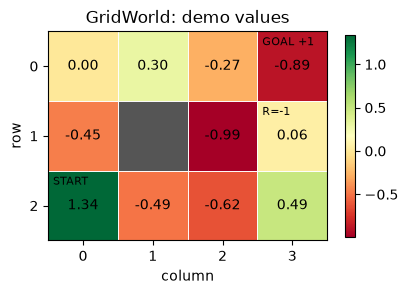

In [3]:
mdp = dlfs4_gridworld()
states = np.arange(mdp.n_states)
print('start:', DLFS4_STATES[DLFS4_START_STATE], '| actions: up, down, left, right')
plot_grid(rng.standard_normal(mdp.n_states), title='GridWorld: demo values')
plt.show()

## 4. Uniform Policy Evaluation — `policy_eval.py`

모든 행동을 1/4로 선택하는 고정 정책의 Vπ를 계산한다. 목표의 V는 0이다.
원본은 제자리 sweep과 허용오차 .001을 사용하지만 여기서는 동기식 API와 1e−10을 사용한다.

sweeps: 148 | V(start): -0.10343315238349912


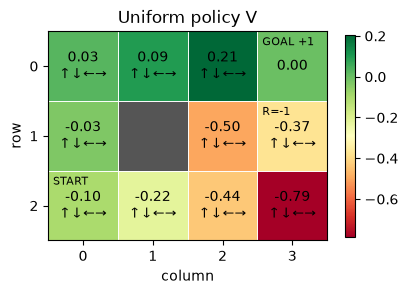

In [4]:
policy = uniform_policy(mdp)
evaluation = policy_evaluation(mdp, policy, gamma=GAMMA, theta=1e-10)
assert evaluation.converged
print('sweeps:', evaluation.iterations, '| V(start):', evaluation.values[DLFS4_START_STATE])
plot_grid(evaluation.values, policy, title='Uniform policy V')
plt.show()

## 5. Policy Improvement — `policy_iter.py`의 개선 단계

$$Q_V(s,a)=\sum_{s',r}p(s',r|s,a)[r+\gamma V(s')]$$

`action_values()`로 행동별 기대값을 보고 `policy_improvement()`로 Greedy Policy를 만든다.
원본 DP는 동률에서 마지막 행동을 택하지만 ModularRL은 같은 최대값 행동에 확률을 균등하게 준다.

Q(start, actions): [-0.02863231 -0.09308984 -0.09308984 -0.19892063]
improved probabilities: [1. 0. 0. 0.]


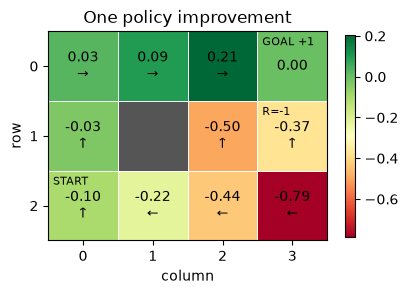

In [5]:
q = action_values(mdp, evaluation.values, gamma=GAMMA)
improved_policy = policy_improvement(mdp, evaluation.values, gamma=GAMMA)
print('Q(start, actions):', q[DLFS4_START_STATE])
print('improved probabilities:', improved_policy[DLFS4_START_STATE])
plot_grid(evaluation.values, improved_policy, title='One policy improvement')
plt.show()

## 6. Policy Iteration — 평가와 개선을 반복하는 공개 API 호출

In [6]:
pi_result = policy_iteration(mdp, gamma=GAMMA, theta=1e-10)
assert pi_result.converged
print('policy cycles:', pi_result.iterations, '| evaluation sweeps:', pi_result.evaluation_iterations)

policy cycles: 5 | evaluation sweeps: 163


## 7. Value Iteration — `value_iter.py`

$$V(s)\leftarrow\max_a Q_V(s,a)$$

Policy Iteration과 별도의 공개 함수를 사용한다. Notebook에 Bellman 반복문을 쓰지 않는다.

value sweeps: 6 | maximum V difference: 0.0


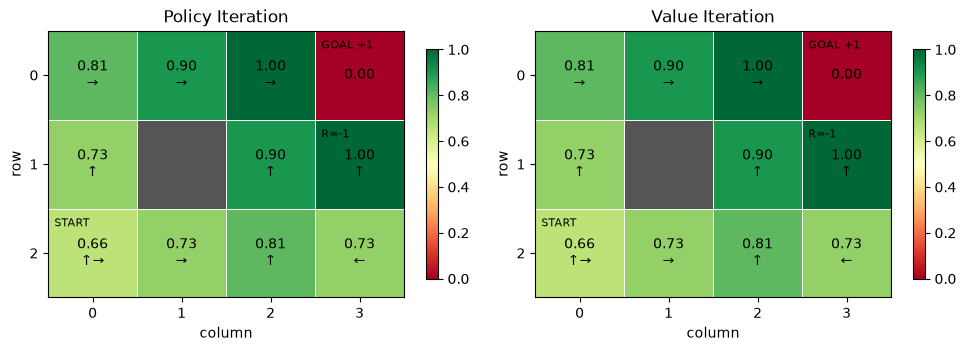

In [7]:
vi_result = value_iteration(mdp, gamma=GAMMA, theta=1e-10)
assert vi_result.converged
np.testing.assert_allclose(pi_result.values, vi_result.values, atol=1e-8)
print('value sweeps:', vi_result.iterations, '| maximum V difference:',
      np.max(np.abs(pi_result.values - vi_result.values)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
plot_grid(pi_result.values, pi_result.policy, title='Policy Iteration', ax=axes[0])
plot_grid(vi_result.values, vi_result.policy, title='Value Iteration', ax=axes[1])
plt.tight_layout()
plt.show()

## 8. 결과 해석

두 방법은 같은 최적 V를 얻는다. 시작에서 목표까지 보상 0인 네 이동과 마지막 +1 이동이므로
V*(start)=0.9⁴=0.6561이다. 목표 칸의 0은 진입 보상 +1이 없다는 뜻이 아니라 **이후 보상이 없다**는 뜻이다.
최적 행동이 여럿이면 정책 배열이 달라도 최적 V는 같을 수 있다.

원본의 제자리 구현과 중간 프레임 반복 표시는 그대로 포팅하지 않았다. 지원 범위와 차이는 대응표에 기록했다.